# Third Practice

### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336

In [32]:
# Necessary libraries
import numpy as np
import math as math
import matplotlib.pyplot as plt

## 1. Introduction task

We define a set of samples form a lineal model with high noise.

In [33]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle), math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
n = 100
points = np.random.multivariate_normal(m,s,n)

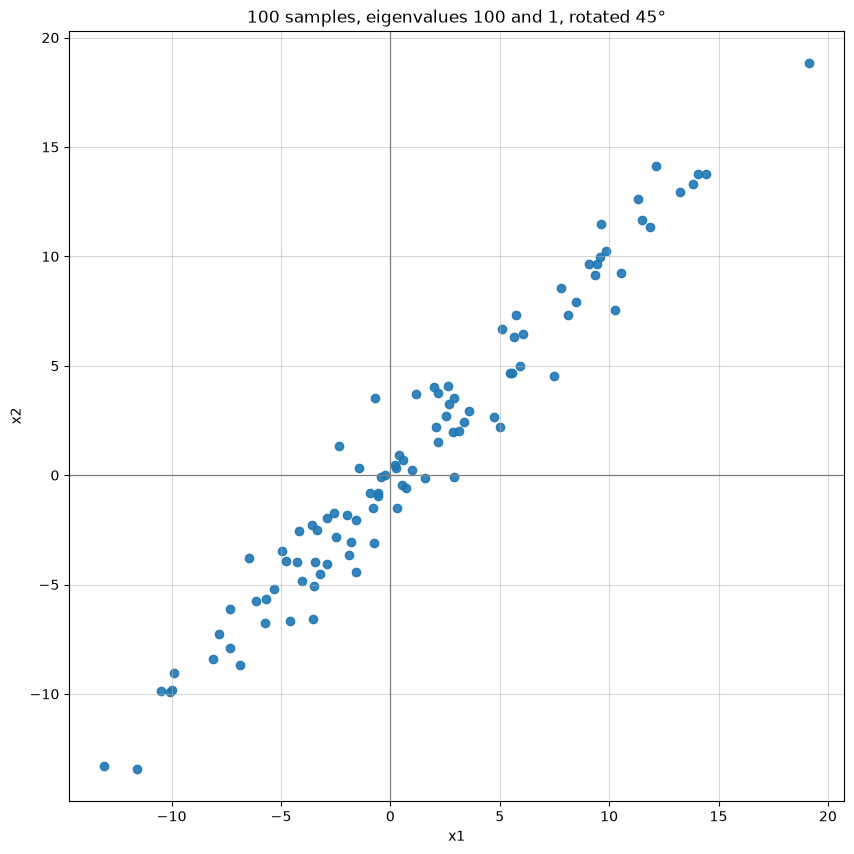

In [34]:
plt.figure(figsize=(10, 10))
plt.scatter(points[:, 0], points[:, 1], alpha=0.9)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"{n} samples, eigenvalues {lamb[0,0]} and {lamb[1,1]}, rotated {int(angle*180/math.pi)}°")
plt.grid(alpha=0.5)
plt.show()


We will now try to find the linear model that fits best the set of points we defined.

Our model will be $w_{1}x + w_{0}$. The goal is to find the parameters $w_{1}$ and $w_{0}$ that minmize a function that might as well be the `Least Squares` function and then use any type of _descent method_ that helps us minimize the function.

#### Loss function model

The loss function model, applied to our case, consists in minimizing $Q$ given a set of points $\{(x_{i},y_{i})\}_{i=1}^{m}$, where $Q$ is the defined as:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(\hat{y}_{i}-y_{i})^{2}
$$

With $\hat{y}_{i} = f_lsm(x_{i})$, the value we expect from our model.

In other words, we want to minimize:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(w_{1}x_{i} + w_{0} - y_{i})^{2}
$$

To do so, we will use the tools from sessions 1 and 2. We consider $Q(w) = Q(w_{0}, w_{1})$ the function to minimize.

As we have done repeatedly in the past, we will calculate the gradient, skipping the calculations for the sake of simplicity and _cleanness_.

$$
\nabla Q =
\begin{pmatrix}
\dfrac{\partial Q}{\partial w_0} \\[2ex]
\dfrac{\partial Q}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i) \\[2ex]
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i)\,x_i
\end{pmatrix}
$$


### 1.1 Implement the Least Squares method

We will use backtracking to minimze $Q(w)$. We will be reusing the code from Session 2.

In [35]:
def LSM(array, w0, w1):
    return (1/2)*np.sum((w1 * array[:, 0] + w0 - array[:, 1])**2)

def LSM_grad(array, w0, w1):
    part_comu = w1 * array[:, 0] + w0 - array[:, 1]
    grad_w0 = np.sum(part_comu)
    grad_w1 = np.sum(part_comu * array[:, 0])
    return np.array([grad_w0, grad_w1])

# I made alpha really small in order to show how the model improves itself
def grad_desc_backtracking(f_lsm, grad_f_lsm, x0, x1, alpha0=0.001, tol=1e-5, max_iter=10000, alpha_min=1e-5):
    x = np.array([x0, x1])
    path = [x]
    alphas = []
    n_halvings = 0
    alpha = alpha0
    for k in range(max_iter):
        grad = grad_f_lsm(x)
        if np.linalg.norm(grad) < tol:
            break
        while f_lsm(x - alpha * grad) >= f_lsm(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x - alpha * grad
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

Model: w_0 = -0.1058, w_1 = 0.9910
This represents a 44.74º angle
719 iterations
7 halvings
LSM = 94.5380


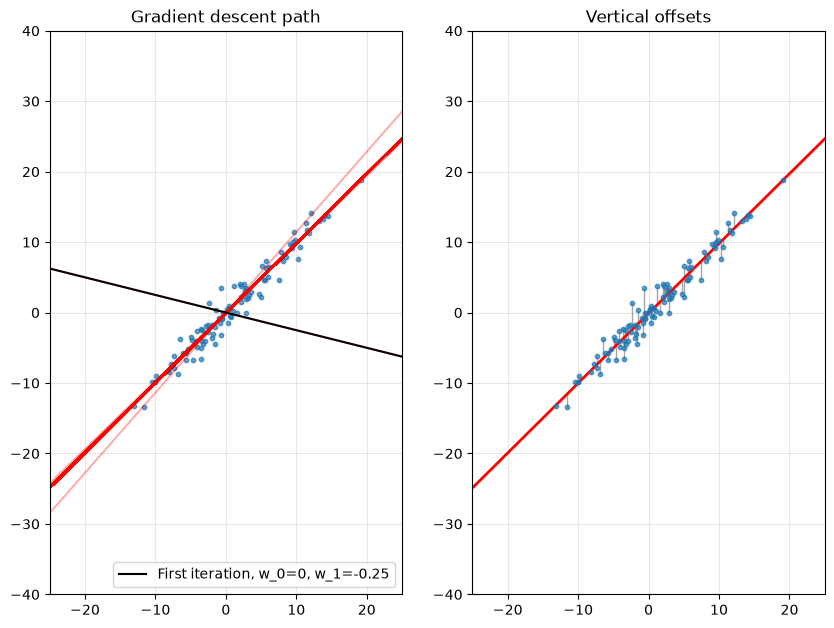

In [36]:
def f_lsm(w):
    return LSM(points, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points, w[0], w[1])

path_LSM, alphas_LSM, n_halvings_LSM = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle_LSM = np.degrees(np.arctan(path_LSM[-1][1]))
print(f"Model: w_0 = {path_LSM[-1][0]:.4f}, w_1 = {path_LSM[-1][1]:.4f}\nThis represents a {angle_LSM:.2f}º angle\n{len(path_LSM)} iterations\n{n_halvings_LSM} halvings\nLSM = {f_lsm(path_LSM[-1]):.4f}")

results_LSM = {"w0": path_LSM[-1][0], "w1": path_LSM[-1][1], "angle": angle_LSM, "iters": len(path_LSM), "Q": f_lsm(path_LSM[-1])}

w0_opt_LSM, w1_opt_LSM = path_LSM[-1]
xs_LSM, ys_LSM = points[:, 0], points[:, 1]
y_hat_LSM = w0_opt_LSM + w1_opt_LSM * xs_LSM
residuals_LSM = ys_LSM - y_hat_LSM

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
#Plot 1
axs[0].scatter(xs_LSM, ys_LSM, alpha=0.7, s=10)
for k in range(len(path_LSM)):
    w0, w1 = path_LSM[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.32 + 0.04 * k / (len(path_LSM) - 1))
axs[0].axline((0,path_LSM[0][0]), slope=path_LSM[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].legend(loc="lower right")
axs[0].set_title("Gradient descent path")

#Plot 2
axs[1].vlines(xs_LSM, y_hat_LSM, ys_LSM, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_LSM, ys_LSM, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_LSM), slope=w1_opt_LSM, color="red", lw=2)
axs[1].set_title("Vertical offsets")

for ax in axs:
    ax.set_xlim(-25, 25)
    ax.set_ylim(-40, 40)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

### 1.2 Outliers influence

In order to show the sensitiviy of our model to outliers we will edit one point of our dataset. This point will now be found at $\left[-40,20\right]$. Then we will compare both models and check the difference when just one point is an outlier.

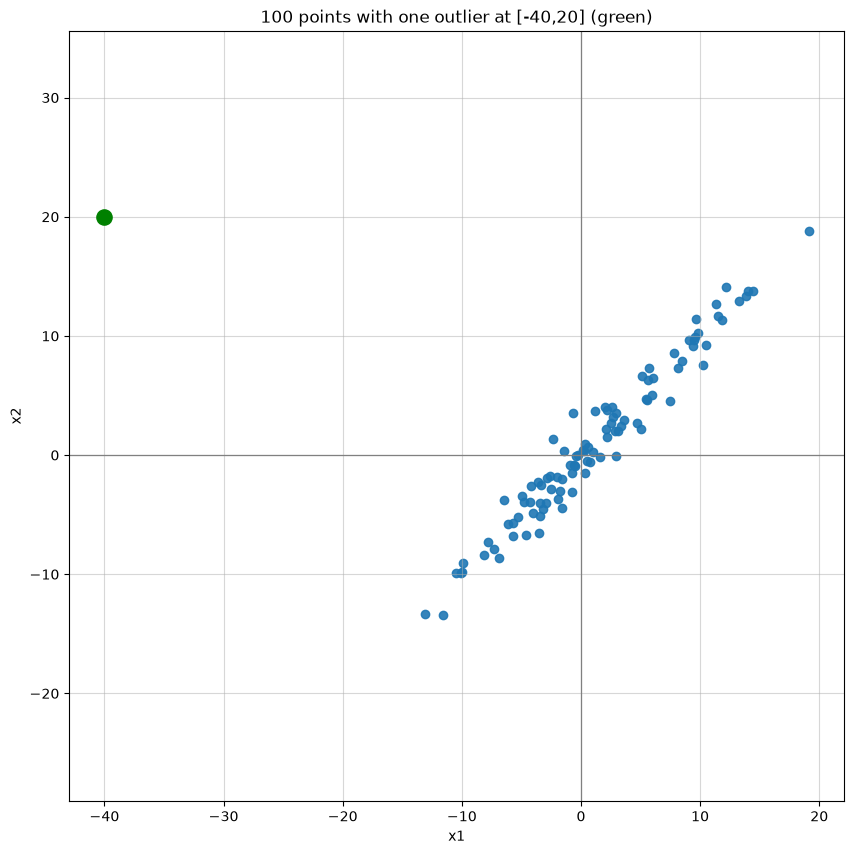

In [37]:
points_one_outlier = points.copy()
points_one_outlier[1] = [-40,20]

plt.figure(figsize=(10, 10))
plt.scatter(points_one_outlier[:, 0], points_one_outlier[:, 1], alpha=0.9)
plt.scatter(*points_one_outlier[1], color="green", s=120, zorder=3)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"100 points with one outlier at [-40,20] (green)")
plt.grid(alpha=0.5)
plt.show()

Now we will repeat section 1.1 but with the edited dataset

Model: w_0 = 0.8114, w_1 = 0.5841
This represents a 30.29º angle
2474 iterations
7 halvings
LSM = 1367.3684


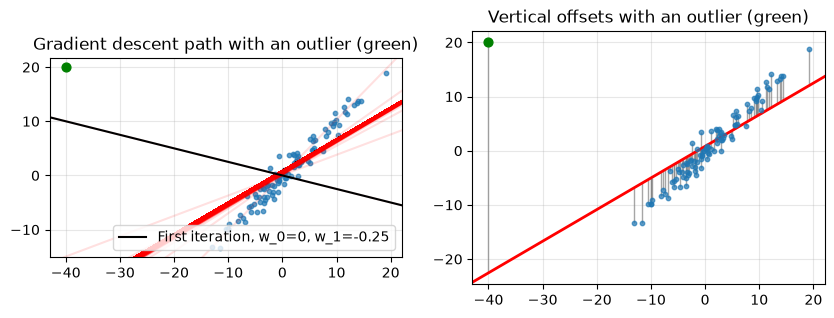

In [38]:
def f_lsm(w):
    return LSM(points_one_outlier, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points_one_outlier, w[0], w[1])

path_LSM_outlier, alphas_LSM_outlier, n_halvings_LSM_outlier = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle_LSM_outlier = np.degrees(np.arctan(path_LSM_outlier[-1][1]))
print(f"Model: w_0 = {path_LSM_outlier[-1][0]:.4f}, w_1 = {path_LSM_outlier[-1][1]:.4f}\nThis represents a {angle_LSM_outlier:.2f}º angle\n{len(path_LSM_outlier)} iterations\n{n_halvings_LSM_outlier} halvings\nLSM = {f_lsm(path_LSM_outlier[-1]):.4f}")

results_LSM_outlier = {"w0": path_LSM_outlier[-1][0], "w1": path_LSM_outlier[-1][1], "angle": angle_LSM_outlier, "iters": len(path_LSM_outlier), "Q": f_lsm(path_LSM_outlier[-1])}

w0_opt_LSM_outlier, w1_opt_LSM_outlier = path_LSM_outlier[-1]
xs_LSM_outlier, ys_LSM_outlier = points_one_outlier[:, 0], points_one_outlier[:, 1]
y_hat_LSM_outlier = w0_opt_LSM_outlier + w1_opt_LSM_outlier * xs_LSM_outlier
residuals_LSM_outlier = ys_LSM_outlier - y_hat_LSM_outlier

fig, axs = plt.subplots(1, 2, figsize=(10, 8))

#Plot 1
axs[0].scatter(xs_LSM_outlier, ys_LSM_outlier, alpha=0.7, s=10)
for k in range(len(path_LSM_outlier)):
    w0, w1 = path_LSM_outlier[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.12 + 0.04 * k / (len(path_LSM_outlier) - 1))
axs[0].axline((0,path_LSM_outlier[0][0]), slope=path_LSM_outlier[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[0].legend(loc="lower right")
axs[0].set_title("Gradient descent path with an outlier (green)")

#Plot 2
axs[1].vlines(xs_LSM_outlier, y_hat_LSM_outlier, ys_LSM_outlier, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_LSM_outlier, ys_LSM_outlier, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_LSM_outlier), slope=w1_opt_LSM_outlier, color="red", lw=2)
axs[1].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[1].set_title("Vertical offsets with an outlier (green)")

for ax in axs:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

We compare the results obtained with and without the outlier:

In [39]:
Q_LSM = LSM(points, w0_opt_LSM, w1_opt_LSM)
Q_LSM_outlier = LSM(points_one_outlier, w0_opt_LSM_outlier, w1_opt_LSM_outlier)

print(f"{'':>10} | {'No outliers':>11} | {'With outliers':>13} | {'Difference %':>12}")
print("-" * 56)
print(f"{'w0':>10} | {w0_opt_LSM:>11.4f} | {w0_opt_LSM_outlier:>13.4f} | {100 * (w0_opt_LSM_outlier - w0_opt_LSM) / abs(w0_opt_LSM):>+11.2f}%")
print(f"{'w1':>10} | {w1_opt_LSM:>11.4f} | {w1_opt_LSM_outlier:>13.4f} | {100 * (w1_opt_LSM_outlier - w1_opt_LSM) / abs(w1_opt_LSM):>+11.2f}%")
print(f"{'Angle':>10} | {angle_LSM:>11.2f} | {angle_LSM_outlier:>13.2f} | {100 * (angle_LSM_outlier - angle_LSM) / abs(angle_LSM):>+11.2f}%")
print(f"{'Iterations':>10} | {len(path_LSM):>11} | {len(path_LSM_outlier):>13} | {100 * (len(path_LSM_outlier) - len(path_LSM)) / len(path_LSM):>+11.2f}%")
print(f"{'Q(w)':>10} | {Q_LSM:>11.2f} | {Q_LSM_outlier:>13.2f} | {100 * (Q_LSM_outlier - Q_LSM) / abs(Q_LSM):>+11.2f}%")


           | No outliers | With outliers | Difference %
--------------------------------------------------------
        w0 |     -0.1058 |        0.8114 |     +866.68%
        w1 |      0.9910 |        0.5841 |      -41.06%
     Angle |       44.74 |         30.29 |      -32.30%
Iterations |         719 |          2474 |     +244.09%
      Q(w) |       94.54 |       1367.37 |    +1346.37%


Without the outlier the model recovers the structure of the data almost perfectly. The points were generated along the 45º direction, meaning $w_{1} = 1$ and $w_{0} = 0$ and we obtain $w_1 = 0.9643$ (43.96º) and $w_0 = 0.1447$.
Changing a single point out of 100 rotates the line by about 12º, and the slope drops about 30%.

With the no outlier model, the point $[-40, 20]$ would contribute approximately $\frac{1}{2}\cdot 58^2 \approx 1700$ to $Q$ on its own, more than 20 times the $Q$ of all the other points together (73.24). Since the gradient of each term is proportional to its residual, the outlier dominates the descent direction, and the optimum becomes a line that sacrifices the fit of the 99 non-outlier points to reduce that single error.

The final $Q$ increases by about 1700%, in the outlier model the outlier still has a contribution of $\frac{1}{2}44^{2}\approx 970$, so the remaining 99 points contribute about 390, roughly five times worse than in the no outliers model.

The method needs about 4 times as many iterations from 561 to 2331. The Least Squares model is very sensitive to outliers, one bad sample has been enough to change the fitted model.

## 2 Robust function

We have seen the sensitivity of the Least Squares Method. We shall use functions that are more robust to outliers. The general function we will minimize is:

$$
\sum_{i=1}^{m} \rho(u_{i})
$$

where $u_{i}$ is the prediction error of the point $i$. in our case:

$$
u_{i} = \hat{y}_{i} - y_{i} = w_{1}x_{i} + w_{0} - y_{i}
$$

and $\rho(u)$ is a robust error function. The Least Squares method is just the case $\rho(u) = \frac{1}{2}u^{2}$.

We will use the Cauchy function, defined as:

$$
\rho(u) = \frac{c^{2}}{2} \log\left[1 + \left(\frac{u}{c}\right)^{2}\right]
$$

where $c \in \mathbb{R}$ is a parameter, we will take $c = 1$. Applied to our model, the function to minimize is:

$$
C(w_{0}, w_{1}) = \frac{c^{2}}{2} \sum_{i=1}^{m} \log\left[1 + \frac{(w_{1}x_{i} + w_{0} - y_{i})^{2}}{c^{2}}\right]
$$

Using the chain rule, the derivative of $\rho$ with respect to $u$ is:

$$
\rho'(u) = \frac{c^{2}}{2} \cdot \frac{2u/c^{2}}{1 + (u/c)^{2}} = \frac{u}{1 + (u/c)^{2}}
$$

and since $\dfrac{\partial u_{i}}{\partial w_{0}} = 1$ and $\dfrac{\partial u_{i}}{\partial w_{1}} = x_{i}$, the gradient is:

$$
\nabla C =
\begin{pmatrix}
\dfrac{\partial C}{\partial w_0} \\[2ex]
\dfrac{\partial C}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}} \\[4ex]
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}}\,x_i
\end{pmatrix}
$$


In [40]:
def cauchy(array, w0, w1, c=1):
    return ((c**2)/2)*np.sum(np.log(1+((w1 * array[:, 0] + w0 - array[:, 1])**2)/(c**2)))

def cauchy_grad(array, w0, w1, c=1):
    part_comu = w1 * array[:, 0] + w0 - array[:, 1]
    weight = part_comu / (1 + (part_comu**2)/(c**2))
    grad_w0 = np.sum(weight)
    grad_w1 = np.sum(weight * array[:, 0])
    return np.array([grad_w0, grad_w1])


### 2.1 Plot the least squares function and compare it with the Cauchy function

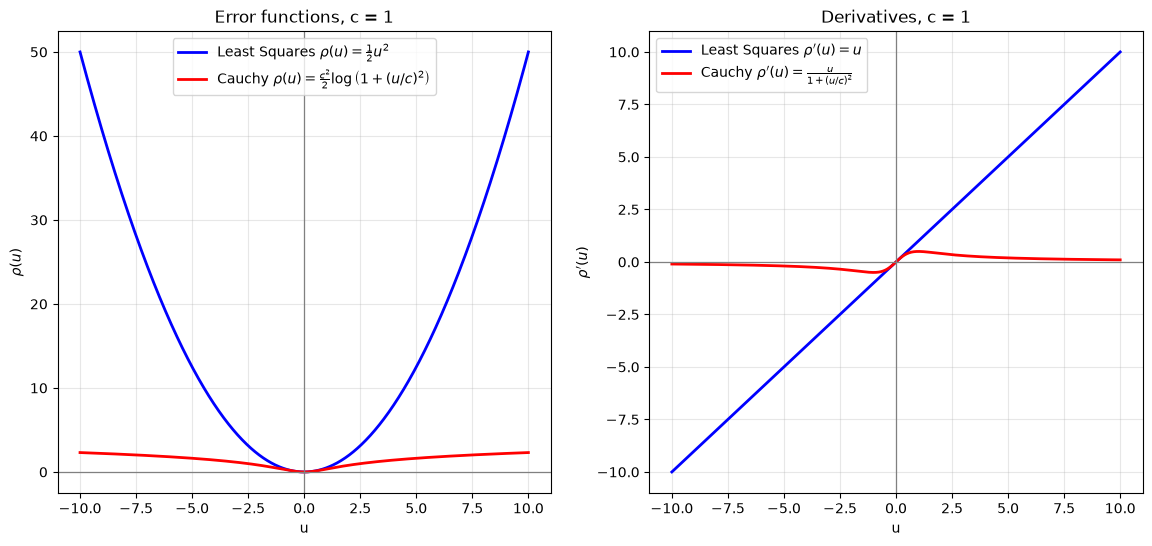

Cauchy(10)        = 0.0990
Least Squares(10) = 10


In [41]:
u = np.linspace(-10, 10, 1000)
c = 1

rho_lsm = (1/2) * u**2
rho_cauchy = ((c**2)/2) * np.log(1 + (u/c)**2)

# Derivatives: how much each error "pulls" on the gradient
drho_lsm = u
drho_cauchy = u / (1 + (u/c)**2)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1
axs[0].plot(u, rho_lsm, color="blue", lw=2, label=r"Least Squares $\rho(u) = \frac{1}{2}u^2$")
axs[0].plot(u, rho_cauchy, color="red", lw=2, label=r"Cauchy $\rho(u) = \frac{c^2}{2}\log\left(1 + (u/c)^2\right)$")
axs[0].set_xlabel("u")
axs[0].set_ylabel(r"$\rho(u)$")
axs[0].legend(loc="upper center")
axs[0].set_title(f"Error functions, c = {c}")

# Plot 2
axs[1].plot(u, drho_lsm, color="blue", lw=2, label=r"Least Squares $\rho'(u) = u$")
axs[1].plot(u, drho_cauchy, color="red", lw=2, label=r"Cauchy $\rho'(u) = \frac{u}{1 + (u/c)^2}$")
axs[1].set_xlabel("u")
axs[1].set_ylabel(r"$\rho'(u)$")
axs[1].legend(loc="upper left")
axs[1].set_title(f"Derivatives, c = {c}")

for ax in axs:
    ax.axhline(0, color="gray", lw=0.9)
    ax.axvline(0, color="gray", lw=0.9)
    ax.grid(alpha=0.3)
plt.show()

print(f"Cauchy(10)        = {10 / (1 + (10/c)**2):.4f}\nLeast Squares(10) = {10:.0f}")


We can see how the contribution of outliers in the least squares method increases as the outlier is further away from the "good" points. On the other hand, the Cauchy function increases slowly, as expected from a logarithm.

For small $u$'s both models are very close, we can see the same pattern for the derivatives. It is known, taught in calculus and real analysis courses, that for small values of $x$, $\log(1+x) \sim x$, therefore, by having $c=1$ and $u$ close to $0$ we see that $\frac{1}{2}\log(1+u^{2}) \sim \frac{1}{2}u^{2}$, so they coincide. The same can be concluded in the derivatives, $\frac{u}{1+u^{2}} \sim u$, the same derivative as the Least Squares.

More importantly, we see that the derivative of the Cauchy function decreases to $0$ as $u$ increases (in absolute value), being under $0.1$ at just $u=10$. Whilst the Least Squares derivative returns $10$ for the same $u$, a value $100$ times larger. This means that a value at (vertical) distance $10$ from a particular step from the model influences $100$ times less the next step of the gradient descent.

### 2.2, 2.3 & 2.4 Cauchy vs LSM

Now we will compare how backtracking differs between the Least Squares method and the Cauchy function. As we have just seen, we are expecting for the Cauchy to behave similarly to LSM when all the points are "good" and to not vary as much whenever outliers appear.

Let's define its gradient descent:

Model: w_0 = -0.0914, w_1 = 0.9877
This represents a 44.64º angle
912 iterations
1 halvings
Q = 36.9176


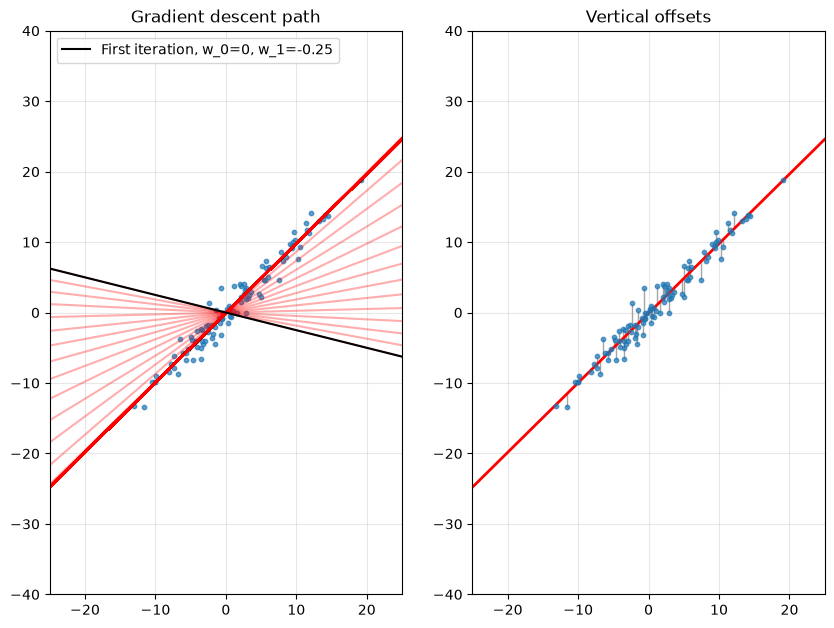

In [42]:
def f_cauchy(w):
    return cauchy(points, w[0], w[1])

def grad_f_cauchy(w):
    return cauchy_grad(points, w[0], w[1])

path_Cauchy, alphas_Cauchy, n_halvings_Cauchy = grad_desc_backtracking(f_cauchy, grad_f_cauchy, 0, -0.25)
angle_Cauchy = np.degrees(np.arctan(path_Cauchy[-1][1]))
print(f"Model: w_0 = {path_Cauchy[-1][0]:.4f}, w_1 = {path_Cauchy[-1][1]:.4f}\nThis represents a {angle_Cauchy:.2f}º angle\n{len(path_Cauchy)} iterations\n{n_halvings_Cauchy} halvings\nQ = {f_cauchy(path_Cauchy[-1]):.4f}")

results_Cauchy = {"w0": path_Cauchy[-1][0], "w1": path_Cauchy[-1][1], "angle": angle_Cauchy, "iters": len(path_Cauchy), "Q": f_cauchy(path_Cauchy[-1])}

w0_opt_Cauchy, w1_opt_Cauchy = path_Cauchy[-1]
xs_Cauchy, ys_Cauchy = points[:, 0], points[:, 1]
y_hat_Cauchy = w0_opt_Cauchy + w1_opt_Cauchy * xs_Cauchy
residuals_Cauchy = ys_Cauchy - y_hat_Cauchy

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
#Plot 1
axs[0].scatter(xs_Cauchy, ys_Cauchy, alpha=0.7, s=10)
for k in range(len(path_Cauchy)):
    w0, w1 = path_Cauchy[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.32 + 0.04 * k / (len(path_Cauchy) - 1))
axs[0].axline((0,path_Cauchy[0][0]), slope=path_Cauchy[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].legend(loc="upper left")
axs[0].set_title("Gradient descent path")

#Plot 2
axs[1].vlines(xs_Cauchy, y_hat_Cauchy, ys_Cauchy, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_Cauchy, ys_Cauchy, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_Cauchy), slope=w1_opt_Cauchy, color="red", lw=2)
axs[1].set_title("Vertical offsets")

for ax in axs:
    ax.set_xlim(-25, 25)
    ax.set_ylim(-40, 40)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

We repeat the process adding an outlier at $[-40, 20]$. We will explain the conclusions after this.

Model: w_0 = -0.1118, w_1 = 0.9896
This represents a 44.70º angle
931 iterations
1 halvings
Q = 40.5377


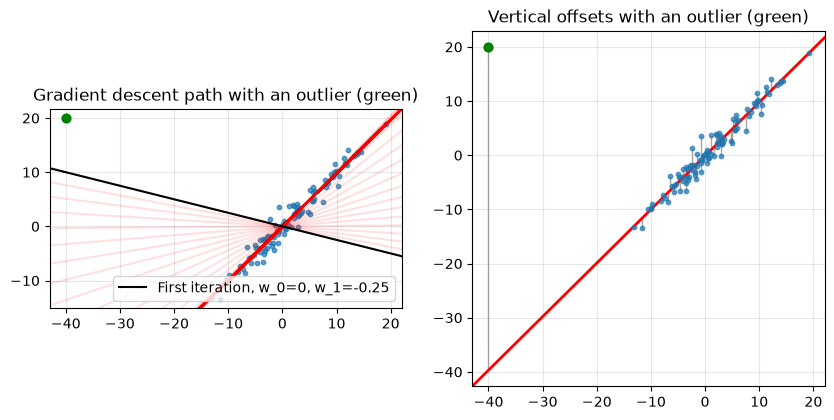

In [65]:
def f_cauchy(w, c=1):
    return cauchy(points_one_outlier, w[0], w[1], c)

def grad_f_cauchy(w, c=1):
    return cauchy_grad(points_one_outlier, w[0], w[1], c)

path_Cauchy_outlier, alphas_Cauchy_outlier, n_halvings_Cauchy_outlier = grad_desc_backtracking(f_cauchy, grad_f_cauchy, 0, -0.25)
angle_Cauchy_outlier = np.degrees(np.arctan(path_Cauchy_outlier[-1][1]))
print(f"Model: w_0 = {path_Cauchy_outlier[-1][0]:.4f}, w_1 = {path_Cauchy_outlier[-1][1]:.4f}\nThis represents a {angle_Cauchy_outlier:.2f}º angle\n{len(path_Cauchy_outlier)} iterations\n{n_halvings_Cauchy_outlier} halvings\nQ = {f_cauchy(path_Cauchy_outlier[-1]):.4f}")

results_Cauchy_outlier = {"w0": path_Cauchy_outlier[-1][0], "w1": path_Cauchy_outlier[-1][1], "angle": angle_Cauchy_outlier, "iters": len(path_Cauchy_outlier), "Q": f_cauchy(path_Cauchy_outlier[-1])}

w0_opt_Cauchy_outlier, w1_opt_Cauchy_outlier = path_Cauchy_outlier[-1]
xs_Cauchy_outlier, ys_Cauchy_outlier = points_one_outlier[:, 0], points_one_outlier[:, 1]
y_hat_Cauchy_outlier = w0_opt_Cauchy_outlier + w1_opt_Cauchy_outlier * xs_Cauchy_outlier
residuals_Cauchy_outlier = ys_Cauchy_outlier - y_hat_Cauchy_outlier

fig, axs = plt.subplots(1, 2, figsize=(10, 8))

#Plot 1
axs[0].scatter(xs_Cauchy_outlier, ys_Cauchy_outlier, alpha=0.7, s=10)
for k in range(len(path_Cauchy_outlier)):
    w0, w1 = path_Cauchy_outlier[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.12 + 0.04 * k / (len(path_Cauchy_outlier) - 1))
axs[0].axline((0,path_Cauchy_outlier[0][0]), slope=path_Cauchy_outlier[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[0].legend(loc="lower right")
axs[0].set_title("Gradient descent path with an outlier (green)")

#Plot 2
axs[1].vlines(xs_Cauchy_outlier, y_hat_Cauchy_outlier, ys_Cauchy_outlier, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_Cauchy_outlier, ys_Cauchy_outlier, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_Cauchy_outlier), slope=w1_opt_Cauchy_outlier, color="red", lw=2)
axs[1].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[1].set_title("Vertical offsets with an outlier (green)")

for ax in axs:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

In [66]:
# SSE on all the points and on the 99 non-outlier points (index 1 is the outlier), to compare both methods with the same measure
def sse(data, w0, w1):
    return np.sum((w1 * data[:, 0] + w0 - data[:, 1])**2)

mask = np.arange(len(points)) != 1
def sse_clean(w0, w1):
    return np.sum((w1 * points[mask, 0] + w0 - points[mask, 1])**2)

rows = [
    ("w0",             [w0_opt_LSM, w0_opt_Cauchy, w0_opt_LSM_outlier, w0_opt_Cauchy_outlier], ".4f"),
    ("w1",             [w1_opt_LSM, w1_opt_Cauchy, w1_opt_LSM_outlier, w1_opt_Cauchy_outlier], ".4f"),
    ("Angle (º)",      [angle_LSM, angle_Cauchy, angle_LSM_outlier, angle_Cauchy_outlier], ".2f"),
    ("Iterations",     [len(path_LSM), len(path_Cauchy), len(path_LSM_outlier), len(path_Cauchy_outlier)], "d"),
    ("Halvings",       [n_halvings_LSM, n_halvings_Cauchy, n_halvings_LSM_outlier, n_halvings_Cauchy_outlier], "d"),
    ("Q",              [results_LSM["Q"], results_Cauchy["Q"], results_LSM_outlier["Q"], results_Cauchy_outlier["Q"]], ".2f"),
    ("SSE",            [sse(points, w0_opt_LSM, w1_opt_LSM), sse(points, w0_opt_Cauchy, w1_opt_Cauchy),
                        sse(points_one_outlier, w0_opt_LSM_outlier, w1_opt_LSM_outlier), sse(points_one_outlier, w0_opt_Cauchy_outlier, w1_opt_Cauchy_outlier)], ".2f"),
    ("SSE 99 points",  [sse_clean(w0_opt_LSM, w1_opt_LSM), sse_clean(w0_opt_Cauchy, w1_opt_Cauchy),
                        sse_clean(w0_opt_LSM_outlier, w1_opt_LSM_outlier), sse_clean(w0_opt_Cauchy_outlier, w1_opt_Cauchy_outlier)], ".2f"),
]

def diff_pct(lsm, cauchy):
    return abs(cauchy - lsm)

print(f"{'':>14} | {'Normal dataset':^38} | {'Outlier dataset':^38}")
print(f"{'':>14} | {'LSM':>10} | {'Cauchy':>10} | {'Diff (abs)':>12} | {'LSM':>10} | {'Cauchy':>10} | {'Diff (abs)':>12}")
print("-" * 97)
for name, v, fmt in rows:
    dfmt = ".0f" if fmt == "d" else ".3f"
    print(f"{name:>14} | {v[0]:>10{fmt}} | {v[1]:>10{fmt}} | {diff_pct(v[0], v[1]):>12{dfmt}} | "
          f"{v[2]:>10{fmt}} | {v[3]:>10{fmt}} | {diff_pct(v[2], v[3]):>12{dfmt}}")

print("\nSSE is the sum of squared distances of all the points (so 2 times LSM).\nSSE 99 points is the sum of squared disances of the non-outlier points.")


               |             Normal dataset             |            Outlier dataset            
               |        LSM |     Cauchy |   Diff (abs) |        LSM |     Cauchy |   Diff (abs)
-------------------------------------------------------------------------------------------------
            w0 |    -0.1058 |    -0.0914 |        0.014 |     0.8114 |    -0.1118 |        0.923
            w1 |     0.9910 |     0.9877 |        0.003 |     0.5841 |     0.9896 |        0.406
     Angle (º) |      44.74 |      44.64 |        0.097 |      30.29 |      44.70 |       14.412
    Iterations |        719 |        912 |          193 |       2474 |        931 |         1543
      Halvings |          7 |          1 |            6 |          7 |          1 |            6
             Q |      94.54 |      36.92 |       57.620 |    1367.37 |      40.54 |     1326.831
           SSE |     189.08 |     189.14 |        0.060 |    2734.74 |    3751.26 |     1016.518
 SSE 99 points |     187.47 |

#### Comparison between LSM and Cauchy with normal dataset

As we can see, with the normal dataset, both models end up yielding extremely similar models, with both $w_{0}$ and $w_{1}$ being less than $0.015$ apart between the two models. The final angle also coincides, with both being almost $45º$.

In terms of how the model performs at finding the minimum, we see that using the Cauchy method took longer but used just one halving in the backtracking gradient descent, meaning that using the Cauchy function, the method doesn't overshoot as much as with Least Squares.

We see that the function to minimize, $Q$, ended up smaller with the Cauchy function, this doesn't directly mean that Cauchy was better in this case. As stated before, both models yield almost the same solution, and Least Squares reached it faster.

To perform a better comparison, we compare the sum of squared distances for both models' solutions. As expected, both solutions end up adding almost the same amount, $187.47$ for Least Squares and $187.63$ for Cauchy, a difference of just $0.157$.

#### Comparison between LSM and Cauchy with the outlier dataset

As we can see, the outlier has a big impact on the Least Squares model whilst the Cauchy model barely changes. Least Squares moves $w_{0}$ to $0.8114$ and $w_{1}$ to $0.5841$, so the angle drops from almost $45º$ to $30.29º$, deviating from the real model. On the other hand, Cauchy ends up with $w_{0} = -0.1118$ and $w_{1} = 0.9896$, an angle of $44.70º$, practically the same as the one it obtained without the outlier.

The same happens with the number of iterations. Least Squares needs $2474$ iterations, more than $3$ times the amount it needed before, as the outlier dominates the gradient and the method is dragged away from the direction of the "good" points. Cauchy needs $931$ iterations, almost the same as before, and it still used just one halving, whilst Least Squares used $7$.

The value of the function to minimize shows the same pattern. $Q$ goes from $94.54$ to $1367.37$ in Least Squares, whilst in Cauchy it goes from $36.92$ to $40.54$. Again, these two values can't be compared directly, but it shows that the outlier almost doesn't contribute to the Cauchy function, as the logarithm grows slowly, as seen in section 2.1.

To perform a fair comparison we use again the sum of squared distances of the $99$ points that are not the outlier. Least Squares ends up with $924.01$, about $5$ times worse than the $187.47$ it got without the outlier. Cauchy ends up with almost the same value as before, so the Cauchy function has basically ignored the outlier. We conclude that Cauchy is a much more robust choice than Least Squares when the data might contain outliers, and that when there are none it gives almost the same solution as Least Squares.


### 2.5 Influence of different $c$ values in the Cauchy function

Normal dataset
       c |       w0 |       w1 | Angle (º) | Iterations | Halvings |           SSE
----------------------------------------------------------------------------------
       1 |  -0.0914 |   0.9877 |     44.64 |        912 |        1 |        189.14
     100 |  -0.1059 |   0.9910 |     44.74 |       4140 |        7 |        189.08
    0.01 |   0.0918 |   0.9552 |     43.69 |     100001 |       20 |        197.12
   0.001 |  -0.8383 |   1.0287 |     45.81 |     100001 |       27 |        242.80
     LSM |  -0.1058 |   0.9910 |     44.74 |        719 |        7 |        189.08

Outlier dataset
       c |       w0 |       w1 | Angle (º) | Iterations | Halvings | SSE 99 points
----------------------------------------------------------------------------------
       1 |  -0.1118 |   0.9896 |     44.70 |        931 |        1 |        187.49
     100 |   0.6963 |   0.6345 |     32.39 |       4143 |        7 |        753.84
    0.01 |   0.1420 |   0.9670 |     44.04 |     100001

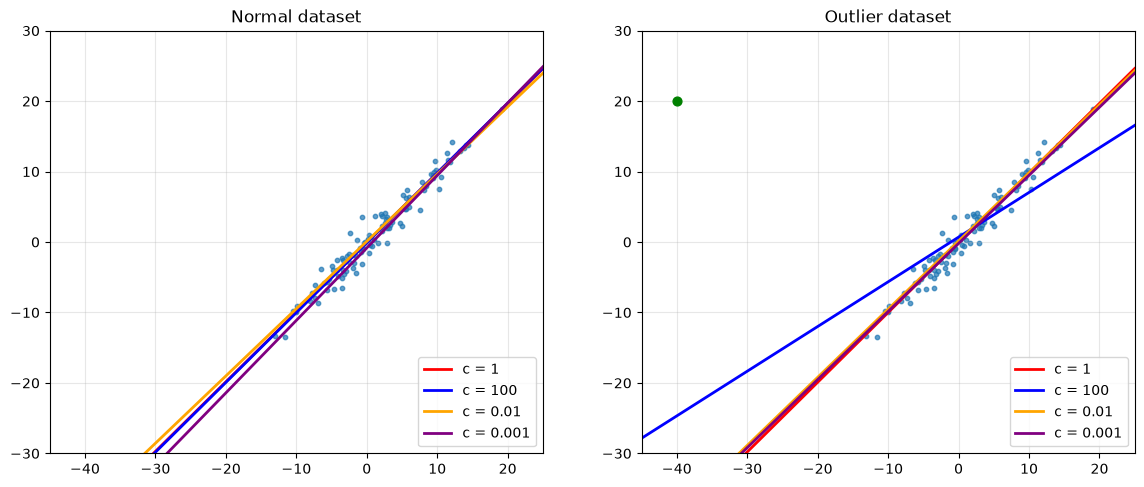

In [70]:
# Approx Claude prompt (summarizing the different steps it took):
#       Can you create a table that shows the different stats from before comparing Cauchy models with c=1, 100, 0.01 and 0.001, add also the LSM for reference
#       Also make plots as the ones from section 1.1 showing the last solution yielded by all the possible models, now not including LSM

#       Further prompts were to clean the presentation and remove insights it proposed...

c_values = [1, 100, 1/100, 1/1000]
datasets = {"Normal dataset": points, "Outlier dataset": points_one_outlier}
max_iter_c = 100000

sse_used = {"Normal dataset": ("SSE", lambda w0, w1: sse(points, w0, w1)),
            "Outlier dataset": ("SSE 99 points", sse_clean)}

results_c = {}
for dataset_name, data in datasets.items():
    for c_val in c_values:
        scale = min(1, c_val**2)
        f = lambda w: cauchy(data, w[0], w[1], c_val)
        grad_f = lambda w: cauchy_grad(data, w[0], w[1], c_val)
        path_c, alphas_c, n_halvings_c = grad_desc_backtracking(f, grad_f, 0, -0.25, alpha0=0.001/scale, tol=1e-5*scale, max_iter=max_iter_c)
        w0_c, w1_c = path_c[-1]
        results_c[(dataset_name, c_val)] = {"w0": w0_c, "w1": w1_c, "angle": np.degrees(np.arctan(w1_c)), "iters": len(path_c),
                                            "halvings": n_halvings_c, "sse": sse_used[dataset_name][1](w0_c, w1_c)}

# Least Squares for comparison
results_LSM_ref = {"Normal dataset": {"w0": w0_opt_LSM, "w1": w1_opt_LSM, "angle": angle_LSM, "iters": len(path_LSM), "halvings": n_halvings_LSM, "sse": sse_used["Normal dataset"][1](w0_opt_LSM, w1_opt_LSM)},
                   "Outlier dataset": {"w0": w0_opt_LSM_outlier, "w1": w1_opt_LSM_outlier, "angle": angle_LSM_outlier, "iters": len(path_LSM_outlier), "halvings": n_halvings_LSM_outlier, "sse": sse_used["Outlier dataset"][1](w0_opt_LSM_outlier, w1_opt_LSM_outlier)}}

for dataset_name in datasets:
    print(f"{dataset_name}")
    print(f"{'c':>8} | {'w0':>8} | {'w1':>8} | {'Angle (º)':>9} | {'Iterations':>10} | {'Halvings':>8} | {sse_used[dataset_name][0]:>13}")
    print("-" * 82)
    for c_val in c_values:
        r = results_c[(dataset_name, c_val)]
        print(f"{c_val:>8g} | {r['w0']:>8.4f} | {r['w1']:>8.4f} | {r['angle']:>9.2f} | {r['iters']:>10} | {r['halvings']:>8} | {r['sse']:>13.2f}")
    r = results_LSM_ref[dataset_name]
    print(f"{'LSM':>8} | {r['w0']:>8.4f} | {r['w1']:>8.4f} | {r['angle']:>9.2f} | {r['iters']:>10} | {r['halvings']:>8} | {r['sse']:>13.2f}\n")

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
colors = ["red", "blue", "orange", "purple"]
for ax, (dataset_name, data) in zip(axs, datasets.items()):
    ax.scatter(data[:, 0], data[:, 1], alpha=0.7, s=10)
    if dataset_name == "Outlier dataset":
        ax.scatter(*data[1], color="green", s=40, zorder=3)
    for c_val, color in zip(c_values, colors):
        r = results_c[(dataset_name, c_val)]
        ax.axline((0, r["w0"]), slope=r["w1"], color=color, lw=2, label=f"c = {c_val:g}")
    ax.set_xlim(-45, 25)
    ax.set_ylim(-30, 30)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
    ax.set_title(f"{dataset_name}")
plt.show()

There are a few conclusions we can obtain with the table and the plots.

If we recall the gradient

$$
\nabla C =
\begin{pmatrix}
\dfrac{\partial C}{\partial w_0} \\[2ex]
\dfrac{\partial C}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}} \\[4ex]
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}}\,x_i
\end{pmatrix}
$$

We see that having $c$ being small, will make each summand of the gradient be small, therefore the models advance to the solution much slower. This can be ascertained in the table, where the $10,000$ step limit implemented in the algorithm was reached by $c \in \{ 0.01, 0.001 \}$. But we can see that in both cases, even though both models reached the step limit, they reached a robust solution in the outlier case, just as $c = 1$. The same amoun

By contrast, $c = 100$ reached a closer solution to $c = 1$ and the Least Squares method. 